In [ ]:
import csv
import inspect
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from IPython.display import display, SVG
from matplotlib.ticker import FormatStrFormatter
from scipy import stats


COLOR_DICT = {
    "desmin": "#CC3311",
    "actin": "#0077BB",
    "actinin": "#009988",
    "myosin": "#BBBBBB",
}
PROTEINS = ("actin", "actinin", "myosin")
LABEL_DICT = {"actin": "Actin", "actinin": "α-actinin", "myosin": "Myosin"}

In [ ]:
def load_pearsons(csv_path):
    """Read named columns; reject missing/invalid observations rather than omit.

    Each column is treated as a separate group, matching the supplied analysis.
    No normalization, Fisher transformation, or rounding is applied.
    """
    values = {p: [] for p in PROTEINS}
    with Path(csv_path).open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        missing = set(LABEL_DICT.values()) - set(reader.fieldnames or ())
        if missing:
            raise ValueError(f"CSV is missing columns: {sorted(missing)}")
        for row_number, row in enumerate(reader, start=2):
            for protein in PROTEINS:
                column = LABEL_DICT[protein]
                try:
                    value = float(row[column])
                except (ValueError, TypeError) as exc:
                    raise ValueError(
                        f"Row {row_number}, {column}: expected a numeric value."
                    ) from exc
                if not np.isfinite(value) or not -1 <= value <= 1:
                    raise ValueError(
                        f"""Row {row_number}, {column}: Pearson r must be finite and in 
                        [-1, 1]."""
                    )
                values[protein].append(value)
    values = {p: np.asarray(v, dtype=float) for p, v in values.items()}
    for protein, v in values.items():
        if v.size < 2 or np.ptp(v) == 0:
            raise ValueError(
                f"{LABEL_DICT[protein]} needs at least two observations with "
                "nonzero variance for this violin/Welch/Games-Howell workflow."
            )
    return values


def format_pvalue(p, threshold=1e-4):
    """Use a bound for tiny p-values, otherwise report the computed value."""
    if threshold is not None and p < threshold:
        return rf"$p < {threshold:g}$"
    if p < 0.001:
        return rf"$p = {p:.2g}$"
    return rf"$p = {p:.3f}$"


def make_pearson_violin_panel(
    csv_path,
    *,
    figsize=(4.5, 5.5),
    colors=None,
    font_size=16,
    tick_size=14,
    annotation_size=12,
    violin_facecolor="#F2F2F2",
    violin_edgecolor="#555555",
    violin_linewidth=0.8,
    violin_width=0.5,
    bw_method=None,
    point_size=25,
    point_edgecolor="#333333",
    point_linewidth=0.6,
    jitter=0.07,
    seed=11,
    bracket_gap=0.02,
    bracket_rise=0.035,
    bracket_linewidth=1.1,
    bracket_heights=None,
    p_threshold=1e-4,
    p_formatter=None,
    ylim=None,
    yticks=None,
    show_n=False,
    grid_axis="y",
):
    """Build the entire annotated panel and return (fig, ax, info).

    figsize: width, height in inches.
    point_size: marker area in points squared; all three groups use circles.
    jitter: horizontal displacement only, in category-axis units.
    bw_method: Matplotlib KDE bandwidth; None retains its default (Scott).
    bracket_gap/rise: vertical distances in Pearson-r units.
    bracket_heights: optional dict keyed by protein pairs, e.g.
        {('actinin', 'myosin'): .45, ('actin', 'actinin'): .65,
         ('actin', 'myosin'): .71}.
        Heights must clear the data and previously drawn brackets.
    p_threshold: show p < this value for smaller p; None shows numeric p.
    p_formatter: optional callable(p) -> text, overriding format_pvalue.
    ylim: optional explicit axis limits, including space for annotations.
    yticks: optional tick positions; default places 0.1-spaced ticks over
        the observed data range, leaving the top annotation area unticked.
    show_n: optionally include sample sizes beneath the category labels.

    Statistical calculations exactly follow the supplied calls:
    Welch's one-way ANOVA and Games-Howell pairwise comparisons on raw r.
    Bracket labels use the Games-Howell adjusted p-values directly.
    """
    if any(
        "equal_var" not in inspect.signature(f).parameters
        for f in (stats.f_oneway, stats.tukey_hsd)
    ):
        raise ImportError("This script requires SciPy >= 1.16 for equal_var=False.")
    if bracket_gap <= 0 or bracket_rise <= 0:
        raise ValueError("bracket_gap and bracket_rise must be positive.")
    if p_threshold is not None and not 0 < p_threshold < 1:
        raise ValueError("p_threshold must be between 0 and 1, or None.")
    data = load_pearsons(csv_path)
    samples = [data[p] for p in PROTEINS]
    anova = stats.f_oneway(*samples, equal_var=False)
    posthoc = stats.tukey_hsd(*samples, equal_var=False)
    color_map = {**COLOR_DICT, **(colors or {})}
    maxima = np.array([v.max() for v in samples])
    data_min = min(v.min() for v in samples)
    data_max = max(maxima)
    data_span = max(data_max - data_min, 0.1)

    # Short comparisons first; draw the lower one before the higher one.
    pairs = sorted(
        [(0, 1), (1, 2), (0, 2)], key=lambda ij: (ij[1] - ij[0], max(maxima[list(ij)]))
    )
    next_foot = maxima + bracket_gap
    bracket_specs = []
    for i, j in pairs:
        pair = (PROTEINS[i], PROTEINS[j])
        left_foot, right_foot = next_foot[i], next_foot[j]
        height = max(left_foot, right_foot) + bracket_rise
        if bracket_heights is not None:
            height = bracket_heights.get(pair, bracket_heights.get(pair[::-1], height))
        if not np.isfinite(height) or height <= max(left_foot, right_foot):
            raise ValueError(f"Bracket height for {pair} is too low.")
        p = float(posthoc.pvalue[i, j])
        label = p_formatter(p) if p_formatter else format_pvalue(p, p_threshold)
        bracket_specs.append((i, j, left_foot, right_foot, height, label))
        next_foot[i] = next_foot[j] = height + bracket_gap

    top = max(spec[4] for spec in bracket_specs)
    if ylim is None:
        ylim = (data_min - 0.06 * data_span, top + 0.10 * data_span)
    if not (ylim[0] < data_min and ylim[1] > top):
        raise ValueError(
            "ylim must contain all observations and leave space above the brackets."
        )

    rc = {
        "font.size": font_size,
        "font.family": "DejaVu Sans",
        "text.color": "black",
        "axes.labelcolor": "black",
        "xtick.color": "black",
        "ytick.color": "black",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "svg.fonttype": "path",
        "pdf.fonttype": 42,
    }
    with plt.style.context("default"), mpl.rc_context(rc):
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
        ax.set_axisbelow(True)
        ax.grid(axis=grid_axis, ls="--", color="#D6D6D6", lw=0.7)
        parts = ax.violinplot(
            samples,
            positions=[1, 2, 3],
            widths=violin_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            bw_method=bw_method,
        )
        for body in parts["bodies"]:
            body.set_facecolor(violin_facecolor)
            body.set_edgecolor(violin_edgecolor)
            body.set_alpha(1.0)
            body.set_linewidth(violin_linewidth)
            body.set_zorder(2)

        rng = np.random.default_rng(seed)
        point_artists = {}
        for x, protein in enumerate(PROTEINS, start=1):
            v = data[protein]
            point_artists[protein] = ax.scatter(
                x + rng.uniform(-jitter, jitter, v.size),
                v,
                s=point_size,
                marker="o",
                facecolors=color_map[protein],
                edgecolors=point_edgecolor,
                linewidths=point_linewidth,
                alpha=1.0,
                zorder=4,
            )

        brackets, texts = [], []
        for i, j, left_foot, right_foot, height, label in bracket_specs:
            (line,) = ax.plot(
                [i + 1, i + 1, j + 1, j + 1],
                [left_foot, height, height, right_foot],
                color="black",
                lw=bracket_linewidth,
                solid_capstyle="butt",
                zorder=5,
            )
            text = ax.annotate(
                label,
                xy=((i + j + 2) / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=annotation_size,
                color="black",
                zorder=6,
                annotation_clip=False,
            )
            brackets.append(line)
            texts.append(text)

        labels = [
            LABEL_DICT[p] + (f"\n(n = {len(data[p])})" if show_n else "")
            for p in PROTEINS
        ]
        ax.set_xticks([1, 2, 3], labels)
        if yticks is None:
            yticks = np.arange(np.ceil(data_min * 10), np.floor(data_max * 10) + 1) / 10
            yticks[np.isclose(yticks, 0, atol=1e-12)] = 0.0
            if len(yticks) < 2:
                yticks = np.linspace(data_min, data_max, 3)
            else:
                ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
        ax.set_yticks(yticks)
        ax.set_xlim(0.5, 3.5)
        ax.set_ylim(ylim)
        ax.set_ylabel("Pearson correlation coefficient", fontsize=font_size)
        ax.tick_params(labelsize=tick_size)
        ax.spines[["top", "right"]].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#555555")
            ax.spines[side].set_linewidth(0.8)

    info = {
        "data": data,
        "protein_order": PROTEINS,
        "n": {p: len(v) for p, v in data.items()},
        "welch_anova": anova,
        "games_howell": posthoc,
        "pairwise_pvalues": {
            (PROTEINS[i], PROTEINS[j]): float(posthoc.pvalue[i, j])
            for i, j in ((0, 1), (0, 2), (1, 2))
        },
        "violin_parts": parts,
        "points": point_artists,
        "brackets": brackets,
        "annotation_texts": texts,
    }
    return fig, ax, info

In [16]:
fig, ax, info = make_pearson_violin_panel(
    "../../source_data/fig_3/3g.csv",
    figsize=(4.5, 5.5),  # Width, height in inches
    font_size=16,  # Y-axis label
    tick_size=14,
    annotation_size=12,
    violin_facecolor="#F2F2F2",
    violin_edgecolor="#555555",
    violin_linewidth=1.0,
    point_size=35,  # Area in points²
    point_edgecolor="#333333",
    point_linewidth=0.7,
    jitter=0.08,
    seed=11,
    bracket_gap=0.02,  # Clearance in Pearson-r units
    bracket_rise=0.035,
    p_threshold=1e-4,  # Display p < 0.0001 when applicable
    show_n=False,
    bracket_heights={
        ("actinin", "myosin"): 0.45,
        ("actin", "actinin"): 0.65,
        ("actin", "myosin"): 0.73,
    },
)
print("Welch ANOVA:", info["welch_anova"])
for pair, p in info["pairwise_pvalues"].items():
    print(f"Games-Howell, {pair[0]} vs {pair[1]}: {p:.6g}")

Welch ANOVA: F_onewayResult(statistic=np.float64(66.44930483535033), pvalue=np.float64(1.4008782329417916e-11))
Games-Howell, actin vs actinin: 6.97949e-08
Games-Howell, actin vs myosin: 4.75509e-12
Games-Howell, actinin vs myosin: 1.65474e-05


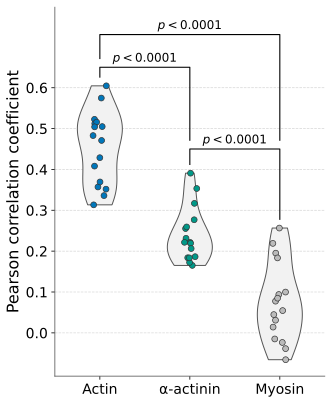

In [18]:
savepath = "../../figures/3g"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)